# 🔗 Live Deployment Link: PASTE_YOUR_STREAMLIT_APP_LINK_HERE

# Heart Disease Prediction System

## Setup
Use the same virtual environment you made for the Titanic project (Python 3.10 to 3.12, packages from the teacher's `requirements.txt`).

Put these files in the **same folder as this notebook**:
- `processed.cleveland.data` (from the UCI download: https://archive.ics.uci.edu/dataset/45/heart+disease)

Then run the cells from top to bottom (Kernel → Restart & Run All).

## Meta Description

**Definition:** A system that predicts whether a person is likely to have heart disease from 4 simple facts.

**Application:** Educational demo of an end-to-end machine learning system (data → model → web app). It is **not** medical advice.

| Input attribute | Meaning | Possible values |
|---|---|---|
| Sex | Sex of the patient | Male, Female |
| ChestPain | Type of chest pain | Typical angina, Atypical angina, Non-anginal pain, Asymptomatic |
| ExerciseAngina | Chest pain brought on by exercise? | Yes, No |
| MaxHeartRate | Highest heart rate reached in the exercise test | Low (below 140), Medium (140-159), High (160+) |

| Output | Meaning | Possible values |
|---|---|---|
| HeartDisease | Is heart disease present? | Yes, No |

**Dataset:** UCI Heart Disease, Cleveland file (`processed.cleveland.data`, 303 rows).
**Algorithm:** Support Vector Classifier (SVC), same as the Titanic notebook.

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction (4 input attributes + target)
- Step 5: Label Encoding the Sample Data
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy the Model (Streamlit Cloud)

## Code — Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
# Numerical computing (arrays, math)
import numpy as np

# Data handling (DataFrames, reading/writing CSV files)
import pandas as pd

# Saving and loading the trained model
import pickle

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

# Convert text categories into numbers
from sklearn.preprocessing import LabelEncoder

# Support Vector Machine model
from sklearn import svm
import sklearn

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Nice tables and charts
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

# Remember this version: the deployed app must use the SAME scikit-learn version
print("scikit-learn version used for training:", sklearn.__version__)

scikit-learn version used for training: 1.7.2


### Step 2: Load Sample Data

In [2]:
# The UCI file has NO header row, so we give the column names ourselves.
# Missing values are written as "?" in this file, so we tell pandas to treat "?" as missing (NaN).
COLUMN_NAMES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

raw_data = pd.read_csv("processed.cleveland.data", header=None, names=COLUMN_NAMES, na_values="?")

print("\n\nRaw Sample Data (first 10 rows):")
print("================================\n")
print(raw_data.head(10))



Raw Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
print("Shape (rows, columns):", raw_data.shape)

print("\n\nAttributes (columns) and their types:")
print("=====================================\n")
print(raw_data.dtypes)

print("\n\nMissing values in each column:")
print("==============================\n")
print(raw_data.isna().sum())

print("\n\nTarget column 'num' (0 = no disease, 1-4 = disease of increasing severity):")
print("==========================================================================\n")
print(raw_data["num"].value_counts().sort_index())

Shape (rows, columns): (303, 14)


Attributes (columns) and their types:

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object


Missing values in each column:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Target column 'num' (0 = no disease, 1-4 = disease of increasing severity):

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


**What the 14 columns mean (we only use the 5 in bold):**

| Column | Meaning |
|---|---|
| age | Age in years |
| **sex** | 1 = male, 0 = female |
| **cp** | Chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| trestbps | Resting blood pressure |
| chol | Cholesterol |
| fbs | Fasting blood sugar > 120 |
| restecg | Resting ECG result |
| **thalach** | Maximum heart rate achieved |
| **exang** | Exercise-induced angina: 1 = yes, 0 = no |
| oldpeak | ST depression |
| slope | Slope of the ST segment |
| ca | Number of major vessels (has some missing values) |
| thal | Thalassemia test result (has some missing values) |
| **num** | **Target**: heart disease (0 = none, 1-4 = present) |

#### Step 3.2: Pre-process Sample Data

In [4]:
# 1. Keep ONLY our 4 input attributes + the target
selected_data = raw_data[["sex", "cp", "exang", "thalach", "num"]].copy()

# 2. Check for missing values in the columns we kept (the missing ones, ca and thal, are not used)
print("Missing values in the selected columns:")
print(selected_data.isna().sum())

# 3. Drop any rows that still have missing values (expected: none)
rows_before = len(selected_data)
selected_data = selected_data.dropna()
print("\nRows dropped because of missing values:", rows_before - len(selected_data))

# 4. Make the target binary: 0 stays 0 (no disease), 1/2/3/4 all become 1 (disease)
selected_data["num"] = (selected_data["num"] > 0).astype(int)

print("\nTarget after making it binary (0 = no disease, 1 = disease):")
print(selected_data["num"].value_counts().sort_index())

Missing values in the selected columns:
sex        0
cp         0
exang      0
thalach    0
num        0
dtype: int64

Rows dropped because of missing values: 0

Target after making it binary (0 = no disease, 1 = disease):
num
0    164
1    139
Name: count, dtype: int64


### Step 4: Feature Extraction

The raw file stores everything as numbers (1, 2, 3, 4...). To follow the Titanic approach, we turn each attribute into **readable words**, and we group the continuous heart rate into 3 levels.

In [5]:
heart_data = pd.DataFrame()

# sex: 1 -> Male, 0 -> Female
heart_data["Sex"] = selected_data["sex"].astype(int).map({1: "Male", 0: "Female"})

# cp: chest pain type
heart_data["ChestPain"] = selected_data["cp"].astype(int).map({
    1: "Typical angina",
    2: "Atypical angina",
    3: "Non-anginal pain",
    4: "Asymptomatic",
})

# exang: exercise-induced angina
heart_data["ExerciseAngina"] = selected_data["exang"].astype(int).map({1: "Yes", 0: "No"})

# thalach: max heart rate -> 3 groups (up to 139 = Low, 140-159 = Medium, 160 and above = High)
heart_data["MaxHeartRate"] = pd.cut(
    selected_data["thalach"],
    bins=[0, 139, 159, 400],
    labels=["Low", "Medium", "High"],
).astype(str)

# Target goes LAST (the Titanic code relies on the target being the last column)
heart_data["HeartDisease"] = selected_data["num"].map({1: "Yes", 0: "No"})

# Safety check: nothing should have failed to convert
assert heart_data.isna().sum().sum() == 0, "Some values could not be converted!"

heart_data.to_csv("heart-data.csv", index=False, header=True)
print("Saved: heart-data.csv")
print("\nShape:", heart_data.shape)
print(heart_data.head(10))

Saved: heart-data.csv

Shape: (303, 5)
      Sex         ChestPain ExerciseAngina MaxHeartRate HeartDisease
0    Male    Typical angina             No       Medium           No
1    Male      Asymptomatic            Yes          Low          Yes
2    Male      Asymptomatic            Yes          Low          Yes
3    Male  Non-anginal pain             No         High           No
4  Female   Atypical angina             No         High           No
5    Male   Atypical angina             No         High           No
6  Female      Asymptomatic             No         High          Yes
7  Female      Asymptomatic            Yes         High           No
8    Male      Asymptomatic             No       Medium          Yes
9    Male      Asymptomatic            Yes       Medium          Yes


#### Step 4.1: Visualize the Data (optional but useful)

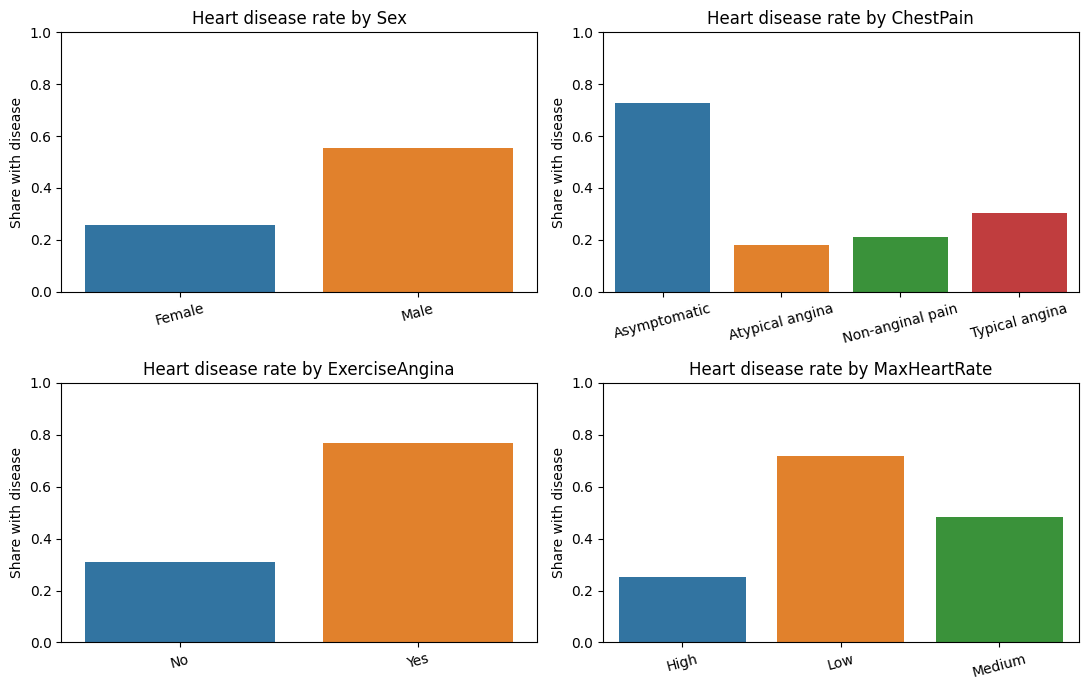

In [6]:
# Share of patients WITH heart disease inside each group of each attribute
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column in zip(axes.ravel(), ["Sex", "ChestPain", "ExerciseAngina", "MaxHeartRate"]):
    rate = heart_data.groupby(column)["HeartDisease"].apply(lambda s: (s == "Yes").mean())
    sns.barplot(x=rate.index, y=rate.values, ax=ax, hue=rate.index, legend=False)
    ax.set_title("Heart disease rate by " + column)
    ax.set_ylabel("Share with disease")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Step 5: Label Encoding the Sample Data

#### Step 5.1: Train the Label Encoder

In [ ]:
# All possible values of each attribute (the same lists will be used again in app.py!)
sex = pd.DataFrame({"Sex": ["Male", "Female"]})
chest_pain = pd.DataFrame({"ChestPain": ["Typical angina", "Atypical angina", "Non-anginal pain", "Asymptomatic"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
max_heart_rate = pd.DataFrame({"MaxHeartRate": ["Low", "Medium", "High"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# One LabelEncoder per column
sex_label_encoder = LabelEncoder()
chest_pain_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
max_heart_rate_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

# Train (fit) the encoders. np.ravel() flattens the 1-column table into a 1D list.
sex_label_encoder.fit(np.ravel(sex))
chest_pain_label_encoder.fit(np.ravel(chest_pain))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
max_heart_rate_label_encoder.fit(np.ravel(max_heart_rate))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show which number each word received (codes follow alphabetical order)
for name, encoder in [("Sex", sex_label_encoder), ("ChestPain", chest_pain_label_encoder),
                      ("ExerciseAngina", exercise_angina_label_encoder),
                      ("MaxHeartRate", max_heart_rate_label_encoder),
                      ("HeartDisease", heart_disease_label_encoder)]:
    print(name, "->", dict(zip(encoder.classes_.tolist(), encoder.transform(encoder.classes_).tolist())))

Sex -> {'Female': 0, 'Male': 1}
ChestPain -> {'Asymptomatic': 0, 'Atypical angina': 1, 'Non-anginal pain': 2, 'Typical angina': 3}
ExerciseAngina -> {'No': 0, 'Yes': 1}
MaxHeartRate -> {'High': 0, 'Low': 1, 'Medium': 2}
HeartDisease -> {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [8]:
heart_data_encoded_output = heart_data.copy()

# Yes/No -> 1/0
heart_data_encoded_output["HeartDisease"] = heart_disease_label_encoder.transform(heart_data["HeartDisease"])

print("HeartDisease After Label Encoding:")
print(pd.concat([heart_data["HeartDisease"], heart_data_encoded_output["HeartDisease"]], axis=1,
                keys=["HeartDisease", "encoded"]).head(10))

heart_data_encoded_output.to_csv("heart-data-encoded-output.csv", index=False, header=True)
print("\nSaved: heart-data-encoded-output.csv")

HeartDisease After Label Encoding:
  HeartDisease  encoded
0           No        0
1          Yes        1
2          Yes        1
3           No        0
4           No        0
5           No        0
6          Yes        1
7           No        0
8          Yes        1
9          Yes        1

Saved: heart-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [9]:
heart_data_encoded = heart_data_encoded_output.copy()

heart_data_encoded["Sex"] = sex_label_encoder.transform(heart_data_encoded_output["Sex"])
heart_data_encoded["ChestPain"] = chest_pain_label_encoder.transform(heart_data_encoded_output["ChestPain"])
heart_data_encoded["ExerciseAngina"] = exercise_angina_label_encoder.transform(heart_data_encoded_output["ExerciseAngina"])
heart_data_encoded["MaxHeartRate"] = max_heart_rate_label_encoder.transform(heart_data_encoded_output["MaxHeartRate"])

print("Sample Data after Label Encoding:")
print("=================================\n")
print(heart_data_encoded.head(10))

heart_data_encoded.to_csv("heart-data-encoded.csv", index=False, header=True)
print("\nSaved: heart-data-encoded.csv")

Sample Data after Label Encoding:

   Sex  ChestPain  ExerciseAngina  MaxHeartRate  HeartDisease
0    1          3               0             2             0
1    1          0               1             1             1
2    1          0               1             1             1
3    1          2               0             0             0
4    0          1               0             0             0
5    1          1               0             0             0
6    0          0               0             0             1
7    0          0               1             0             0
8    1          0               0             2             1
9    1          0               1             2             1

Saved: heart-data-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [10]:
# 80% for training, 20% for testing.
# shuffle=True  : the UCI file is not pre-mixed like the Titanic file, so we mix the rows first
# stratify=...  : keeps the same share of Yes/No in both parts
# random_state=0: same split every time
training_data_encoded, testing_data_encoded = train_test_split(
    heart_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=heart_data_encoded["HeartDisease"],
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [11]:
# Everything except the last column = inputs; the last column = the answer (target)
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vector shape:", input_vector_train.shape)
print("Output label shape:", output_label_train.shape)

Input vector shape: (242, 4)
Output label shape: (242,)


### 6.3: Train the Support Vector Classifier

In [12]:
print("Training the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma='auto', random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)

Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [13]:
with open("heart_disease_svc_model.pkl", "wb") as f:
    pickle.dump(svc_model, f)

print("Saved: heart_disease_svc_model.pkl")
print("Trained with scikit-learn", sklearn.__version__, "(use the same version in requirements.txt)")

Saved: heart_disease_svc_model.pkl
Trained with scikit-learn 1.7.2 (use the same version in requirements.txt)


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [14]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vector shape:", input_vector_test.shape)
print("Output label shape:", output_label_test.shape)

Input vector shape: (61, 4)
Output label shape: (61,)


### Step 7.2: Load the Saved Model

In [15]:
with open("heart_disease_svc_model.pkl", "rb") as f:
    model = pickle.load(f)

print("Model loaded from heart_disease_svc_model.pkl")

Model loaded from heart_disease_svc_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions on the Testing Data

In [16]:
model_predictions = model.predict(input_vector_test)

# Add the predictions next to the real answers so we can compare them
testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

print("Predictions Returned by heart_disease_svc_model:")
print("================================================\n")
print(testing_data_encoded.head(20))

Predictions Returned by heart_disease_svc_model:

     Sex  ChestPain  ExerciseAngina  MaxHeartRate  HeartDisease  Predictions
125    0          1               0             0             0            0
83     1          2               1             2             1            0
53     1          1               0             0             0            0
45     1          2               0             0             1            0
248    1          0               0             0             1            0
211    1          3               1             0             1            0
36     1          0               1             1             1            1
106    1          0               1             0             1            0
120    1          0               1             2             1            1
31     1          0               1             0             1            0
156    1          0               1             0             1            0
157    1          0       

### Step 7.4: Calculate the Accuracy Score

In [17]:
model_accuracy_score = accuracy_score(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"],
)

print("Accuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))

Accuracy Score:

0.72


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)

Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.67      0.94      0.78        33
   Heart Disease (1)       0.87      0.46      0.60        28

            accuracy                           0.72        61
           macro avg       0.77      0.70      0.69        61
        weighted avg       0.76      0.72      0.70        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     31                   2
Actual: Disease                        15                  13


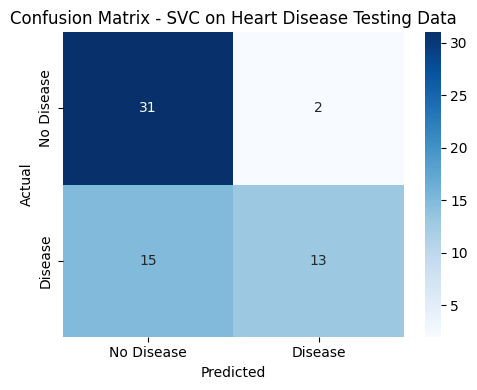

In [18]:
print("Classification Report:")
print("======================\n")
print(classification_report(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"],
))

conf_matrix = confusion_matrix(testing_data_encoded["HeartDisease"], testing_data_encoded["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"],
)
print("\nConfusion Matrix:")
print("=================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [19]:
# Demo patient (edit these values and re-run the cells below).
# Allowed values:
#   Sex            : Male, Female
#   ChestPain      : Typical angina, Atypical angina, Non-anginal pain, Asymptomatic
#   ExerciseAngina : Yes, No
#   MaxHeartRate   : Low, Medium, High
sex_input = "Male"
chest_pain_input = "Asymptomatic"
exercise_angina_input = "Yes"
max_heart_rate_input = "Low"

print(f"Sex: {sex_input}, ChestPain: {chest_pain_input}, ExerciseAngina: {exercise_angina_input}, MaxHeartRate: {max_heart_rate_input}")

Sex: Male, ChestPain: Asymptomatic, ExerciseAngina: Yes, MaxHeartRate: Low


#### Step 8.2: Convert User Input into Feature Vector

In [20]:
# Column names and order MUST match the training data
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chest_pain_input],
    "ExerciseAngina": [exercise_angina_input],
    "MaxHeartRate": [max_heart_rate_input],
})

print("User Input Feature Vector:")
print(user_input)

User Input Feature Vector:
    Sex     ChestPain ExerciseAngina MaxHeartRate
0  Male  Asymptomatic            Yes          Low


#### Step 8.3: Label Encoding of Feature Vector

In [21]:
unseen_data_features = user_input.copy()

unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["MaxHeartRate"] = max_heart_rate_label_encoder.transform(user_input["MaxHeartRate"])

print("User Input Encoded Feature Vector:")
print(unseen_data_features)

User Input Encoded Feature Vector:
   Sex  ChestPain  ExerciseAngina  MaxHeartRate
0    1          0               1             1


### Step 8.4: Load the Saved Model

In [22]:
with open("heart_disease_svc_model.pkl", "rb") as f:
    model = pickle.load(f)

print("Model loaded from heart_disease_svc_model.pkl")

Model loaded from heart_disease_svc_model.pkl


### Step 8.5: Model Prediction

In [23]:
# [0] takes the single answer out of the result list
predicted_disease = model.predict(unseen_data_features)[0]

if predicted_disease == 1:
    prediction = "HEART DISEASE LIKELY"
else:
    prediction = "HEART DISEASE NOT LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts
The rows below are **sample entries for illustration**. After you deploy the app, ask classmates to try it and replace them with their real comments.

In [24]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Student Tester (example)", "Student Tester (example)", "Student Tester (example)"],
    "Case": [
        "Male, Asymptomatic chest pain, Exercise angina Yes, Low heart rate",
        "Female, Typical angina, Exercise angina No, High heart rate",
        "Any patient",
    ],
    "Feedback": [
        "Result looks sensible: this combination is a known warning pattern.",
        "Result looks sensible for a low-risk combination.",
        "Only 4 inputs are used, so the app cannot be very precise.",
    ],
})
print(example_feedback.to_string(index=False))

                Reviewer                                                               Case                                                            Feedback
Student Tester (example) Male, Asymptomatic chest pain, Exercise angina Yes, Low heart rate Result looks sensible: this combination is a known warning pattern.
Student Tester (example)        Female, Typical angina, Exercise angina No, High heart rate                   Result looks sensible for a low-risk combination.
Student Tester (example)                                                        Any patient          Only 4 inputs are used, so the app cannot be very precise.


#### Step 9.2: Make a List of Potential Improvements

In [25]:
improvements = [
    "Use more attributes (age, cholesterol, blood pressure) to give the model more information.",
    "Use cross-validation instead of one 80/20 split for a more reliable accuracy number.",
    "Try other models (Logistic Regression, Decision Tree, Random Forest) and compare them.",
    "Combine more UCI files (Hungarian, Switzerland, VA) to get more training data.",
]
for number, item in enumerate(improvements, start=1):
    print(number, "-", item)

1 - Use more attributes (age, cholesterol, blood pressure) to give the model more information.
2 - Use cross-validation instead of one 80/20 split for a more reliable accuracy number.
3 - Try other models (Logistic Regression, Decision Tree, Random Forest) and compare them.
4 - Combine more UCI files (Hungarian, Switzerland, VA) to get more training data.


#### Step 9.3: Improve the Model Based on Feedback

In [26]:
print("Next version: retrain with more attributes and more data, re-evaluate, then replace heart_disease_svc_model.pkl")

Next version: retrain with more attributes and more data, re-evaluate, then replace heart_disease_svc_model.pkl


## Step 10: Deploy Your Model as a Public Web App
The trained model (`heart_disease_svc_model.pkl`) is deployed with **Streamlit Community Cloud**.

1. Put `app.py`, `heart_disease_svc_model.pkl`, `requirements.txt` and `runtime.txt` in a public GitHub repository.
2. On https://share.streamlit.io choose **Create app** → pick the repository, branch `main`, main file `app.py`.
3. Under **Advanced settings** choose Python 3.11, then **Deploy**.
4. Paste the final app link at the **top of this notebook**.

Live app: **PASTE_YOUR_STREAMLIT_APP_LINK_HERE**

In [27]:
print(f"Final test accuracy of the deployed model: {round(model_accuracy_score, 2)}")

Final test accuracy of the deployed model: 0.72


## Conclusion
We built an end-to-end system: loaded the UCI Heart Disease data, cleaned it, turned 4 attributes into readable categories, label-encoded them, trained an SVC, tested it, saved it and deployed it as a web app.

*(Write your final accuracy and 2-3 sentences about what you observed in the charts and in the confusion matrix.)*